# Семестровая работа по введению в Машинное обучение
## Выполнил Цвиль Павел, группа ФИТ-231
### Задание 2. Классификация



## 1. Загрузка и первичный анализ данных

Загружаем датасет для задачи классификации, задаём имена столбцов (`f0–f6` — признаки, `target` — класс объекта). Проверяем размер таблицы, типы данных, количество пропусков и распределение объектов по классам.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Загружаем датасет
df_clf = pd.read_csv('data/dataset_var8_class.csv', sep=';', header=None)
df_clf.columns = [f'f{i}' for i in range(df_clf.shape[1] - 1)] + ['target']

print('Размер датасета:', df_clf.shape)
print('\nТипы данных и пропуски:')
print(df_clf.info())

print('\nКоличество пропусков в столбцах:')
print(df_clf.isna().sum())

print('\nРаспределение классов (target):')
print(df_clf['target'].value_counts().sort_index())

display(df_clf.describe().round(3))


Размер датасета: (100, 8)

Типы данных и пропуски:
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   f0      95 non-null     float64
 1   f1      95 non-null     float64
 2   f2      100 non-null    float64
 3   f3      100 non-null    float64
 4   f4      100 non-null    float64
 5   f5      100 non-null    float64
 6   f6      100 non-null    float64
 7   target  100 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 6.4 KB
None

Количество пропусков в столбцах:
f0        5
f1        5
f2        0
f3        0
f4        0
f5        0
f6        0
target    0
dtype: int64

Распределение классов (target):
target
0    32
1    35
2    33
Name: count, dtype: int64


,f0,f1,f2,f3,f4,f5,f6,target
count,95.000,95.000,100.000,100.000,100.000,100.000,100.000,100.00
mean,0.433,0.001,-0.125,-0.364,0.849,0.464,-0.364,1.01
std,1.296,1.080,0.957,1.261,1.878,1.884,1.261,0.81
min,-2.177,-2.172,-2.133,-2.341,-3.387,-9.830,-2.341,0.00
25%,-0.712,-0.697,-0.733,-1.351,-0.502,-0.557,-1.351,0.00
50%,0.585,-0.041,-0.051,-0.672,0.585,0.753,-0.672,1.00
75%,1.530,0.702,0.491,0.235,2.003,1.119,0.235,2.00
max,2.718,2.585,2.500,2.863,4.895,6.902,2.863,2.00


### Выводы по первичному анализу:
* В датасете **100 строк и 8 столбцов**: 7 числовых признаков (`f0–f6`) и целевой столбец классов `target` (`0`, `1` и `2`).
* **Пропуски:** по 5 пропусков (5%) обнаружено в признаках `f0` и `f1` — их немного, поэтому позже заполним их медианой.
* **Баланс классов отличный:** объекты распределены почти поровну (`0` — 32 шт., `1` — 35 шт., `2` — 33 шт.), перекоса классов нет.
* **Дубликат признаков:** по описательной статистике видно, что столбцы `f3` и `f6` полностью совпадают по всем показателям


## 2. Корреляционный анализ и отбор признаков

Построим тепловую карту корреляций, чтобы оценить связь признаков с целевым классом `target` и проверить дублирующиеся или шумовые столбцы.


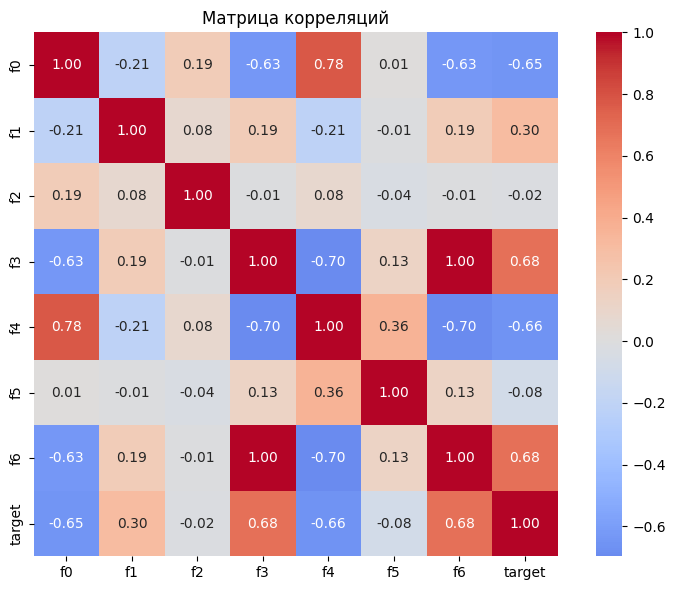

Корреляция признаков с 'target':
f0   -0.6463
f1    0.3046
f2   -0.0201
f3    0.6757
f4   -0.6615
f5   -0.0790
f6    0.6757
Name: target, dtype: float64


In [5]:
plt.figure(figsize=(8, 6))
sns.heatmap(df_clf.corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Матрица корреляций')
plt.tight_layout()
plt.show()

print("Корреляция признаков с 'target':")
print(df_clf.corr(numeric_only=True)['target'].drop('target').sort_index().round(4))


### Выводы по матрице корреляций:
* **Сильные признаки:** хорошую связь с целевым классом `target` показывают **`f3` (`0.6757`)**, **`f4` (`-0.6615`)**, **`f0` (`-0.6463`)** и **`f1` (`0.3046`)** — их обязательно оставляем, а пропуски в `f0` и `f1` заполним медианой.
* **Полный дубликат:** признаки `f3` и `f6` имеют корреляцию **`1.00`** между собой (мультиколлинеарность), поэтому **`f6` удаляем**, чтобы не дублировать один и тот же признак.
* **Шумовые признаки:** **`f2` (`-0.0201`)** и **`f5` (`-0.0790`)** практически не влияют на целевой класс, поэтому их также **удаляем** согласно ТЗ.


In [6]:
# 1. Удаляем дубликат f6 и шумовые признаки f2, f5
df_clf = df_clf.drop(columns=['f2', 'f5', 'f6'])

# 2. Заполняем пропуски в f0 и f1 медианой
df_clf = df_clf.fillna(df_clf.median())

print('Размер датасета после очистки:', df_clf.shape)
print('Оставшиеся столбцы:', list(df_clf.columns))
print('Проверка пропусков:', df_clf.isna().sum().to_dict())


Размер датасета после очистки: (100, 5)
Оставшиеся столбцы: ['f0', 'f1', 'f3', 'f4', 'target']
Проверка пропусков: {'f0': 0, 'f1': 0, 'f3': 0, 'f4': 0, 'target': 0}


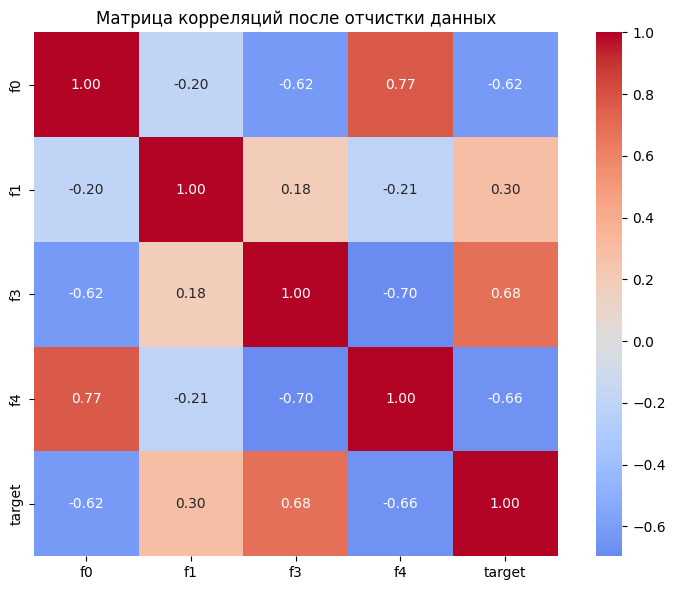

Корреляция признаков с 'target':
f0   -0.6195
f1    0.2959
f3    0.6757
f4   -0.6615
Name: target, dtype: float64


In [7]:
plt.figure(figsize=(8, 6))
sns.heatmap(df_clf.corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Матрица корреляций после отчистки данных')
plt.tight_layout()
plt.show()

print("Корреляция признаков с 'target':")
print(df_clf.corr(numeric_only=True)['target'].drop('target').sort_index().round(4))


#### Вывод после очистки и заполнения пропусков:
* После удаления дубликата (`f6`) и шумовых признаков (`f2`, `f5`) в таблице остались **4 информативных признака (`f0, f1, f3, f4`)** и целевой столбец `target`.
* Заполнение пропусков в `f0` и `f1` медианой практически не изменило их корреляцию с целевым классом (`-0.6195` и `0.2959`).


### 3. Анализ выбросов

Проверим оставшиеся признаки (`f0`, `f1`, `f3`, `f4`) на наличие выбросов с помощью графиков `boxplot` и метода межквартильного размаха (IQR).


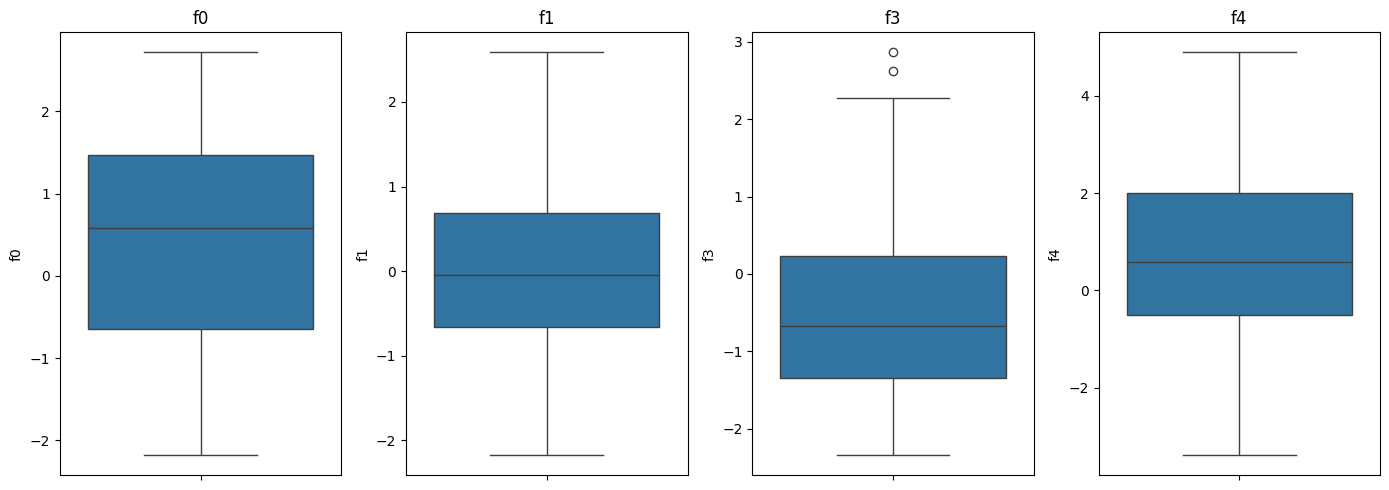

Количество выбросов в признаках (по IQR):
f0: 0 шт. (0.0%)
f1: 0 шт. (0.0%)
f3: 2 шт. (2.0%)
f4: 0 шт. (0.0%)


In [8]:
features_clf = ['f0', 'f1', 'f3', 'f4']

fig, axes = plt.subplots(1, len(features_clf), figsize=(14, 5))
for ax, col in zip(axes, features_clf):
    sns.boxplot(y=df_clf[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

print("Количество выбросов в признаках (по IQR):")
for col in features_clf:
    Q1 = df_clf[col].quantile(0.25)
    Q3 = df_clf[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df_clf[(df_clf[col] < lower) | (df_clf[col] > upper)]
    print(f'{col}: {len(outliers)} шт. ({len(outliers)/len(df_clf)*100:.1f}%)')


### Вывод по анализу выбросов:
* Данные очень чистые: в признаках `f0`, `f1` и `f4` выбросов нет вообще (`0%`), а в `f3` найдены всего **2 незначительных выброса (`2.0%`)**.


## 4. Разбиение данных на train и test и масштабирование

Отделяем признаки `X` от целевого класса `target`. Делим выборку на тренировочную (`60%` — 60 строк) и тестовую (`40%` — 40 строк) с параметром `stratify=y`, чтобы пропорция всех трёх классов сохранилась в обеих частях.

Также выполняем масштабирование (`StandardScaler`) для метода ближайших соседей (`KNeighborsClassifier`), так как он вычисляет расстояния между точками.


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Отделяем признаки X и целевой класс y
X_clf = df_clf.drop(columns=['target'])
y_clf = df_clf['target']

# 2. Разбиваем на 60/40 с сохранением баланса классов (stratify)
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_clf, y_clf, test_size=0.4, random_state=42, stratify=y_clf
)

# 3. Масштабируем данные (для KNN)
scaler_c = StandardScaler()
X_train_c_scaled = scaler_c.fit_transform(X_train_c)
X_test_c_scaled = scaler_c.transform(X_test_c)

print('Размер X_train:', X_train_c.shape)
print('Размер X_test:', X_test_c.shape)
print('\nРаспределение классов в тесте (y_test):')
print(y_test_c.value_counts().sort_index())


Размер X_train: (60, 4)
Размер X_test: (40, 4)

Распределение классов в тесте (y_test):
target
0    13
1    14
2    13
Name: count, dtype: int64


## 5. Построение моделей классификации

### 5.1. Модель 1: RandomForestClassifier (Случайный лес)

**Случайный лес для классификации** строит множество независимых решающих деревьев на случайных подвыборках данных. При предсказании каждое дерево «голосует» за один из классов (`0`, `1` или `2`), а итоговым ответом модели становится класс, набравший большинство голосов.

Деревьям не требуется масштабирование признаков. Сначала обучим базовую модель из коробки, а затем подберём оптимальные параметры.


In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Обучаем стандартный случайный лес
rf_clf_base = RandomForestClassifier(random_state=42)
rf_clf_base.fit(X_train_c, y_train_c)

# 2. Делаем предсказания на тесте
y_pred_rf_c_base = rf_clf_base.predict(X_test_c)

# 3. Выводим accuracy (score) и подробные метрики по классам
acc_rf_base = rf_clf_base.score(X_test_c, y_test_c)
print(f'Стандартный RandomForestClassifier -> Accuracy (score): {acc_rf_base:.4f}\n')
print('Отчёт по метрикам (classification_report):')
print(classification_report(y_test_c, y_pred_rf_c_base))


Стандартный RandomForestClassifier -> Accuracy (score): 0.8000

Отчёт по метрикам (classification_report):
              precision    recall  f1-score   support

           0       0.69      0.69      0.69        13
           1       0.85      0.79      0.81        14
           2       0.86      0.92      0.89        13

    accuracy                           0.80        40
   macro avg       0.80      0.80      0.80        40
weighted avg       0.80      0.80      0.80        40



#### Вывод по базовому RandomForestClassifier:
* Стандартный случайный лес показал точность **Accuracy (score) = 0.8000** (правильно классифицированы 32 из 40 тестовых объектов).
* По отчёту `classification_report` видно, что модель лучше всего распознаёт **класс `2` (`f1-score = 0.89`)** и **класс `1` (`0.81`)**, а больше всего ошибок допускает на **классе `0` (`0.69`)**.

Далее проверим на графике влияние глубины деревьев (`max_depth`) и подберём оптимальные параметры для улучшения результата.


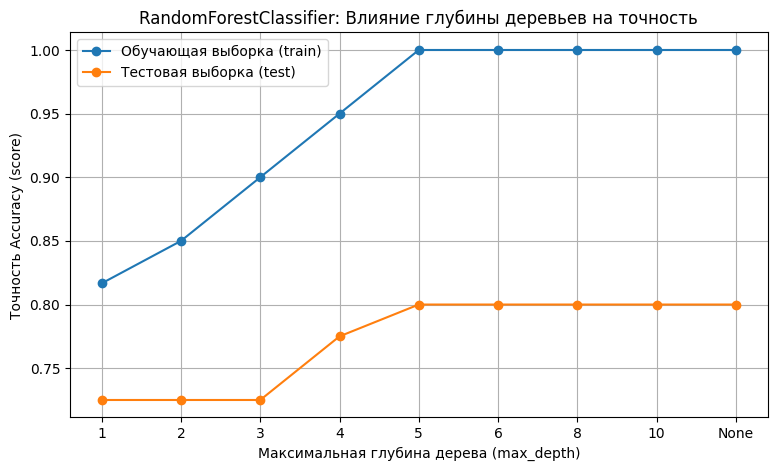

Лучшие параметры RandomForestClassifier: {'n_estimators': 50, 'max_depth': 3, 'min_samples_leaf': 4}
Стандартный RandomForest Accuracy: 0.8000
Настроенный RandomForest Accuracy: 0.8250


In [11]:
# 1. График зависимости Accuracy от глубины деревьев (max_depth)
depths_c = (1, 2, 3, 4, 5, 6, 8, 10, None)
rf_c_train_scores = []
rf_c_test_scores = []

for d in depths_c:
    rf = RandomForestClassifier(max_depth=d, random_state=42)
    rf.fit(X_train_c, y_train_c)
    rf_c_train_scores.append(rf.score(X_train_c, y_train_c))
    rf_c_test_scores.append(rf.score(X_test_c, y_test_c))

depth_labels_c = [str(d) for d in depths_c]

plt.figure(figsize=(9, 5))
plt.plot(depth_labels_c, rf_c_train_scores, marker='o', label='Обучающая выборка (train)')
plt.plot(depth_labels_c, rf_c_test_scores, marker='o', label='Тестовая выборка (test)')
plt.xlabel('Максимальная глубина дерева (max_depth)')
plt.ylabel('Точность Accuracy (score)')
plt.title('RandomForestClassifier: Влияние глубины деревьев на точность')
plt.legend()
plt.grid(True)
plt.show()

# 2. Перебор параметров (n_estimators, max_depth, min_samples_leaf)
best_rf_c_score = -999
best_rf_c_params = {}

for n_est in (50, 100, 200):
    for depth in (2, 3, 4, 5, 6, 8, None):
        for min_leaf in (1, 2, 4):
            rf = RandomForestClassifier(
                n_estimators=n_est,
                max_depth=depth,
                min_samples_leaf=min_leaf,
                random_state=42
            )
            rf.fit(X_train_c, y_train_c)
            score = rf.score(X_test_c, y_test_c)
            
            if score > best_rf_c_score:
                best_rf_c_score = score
                best_rf_c_params = {
                    'n_estimators': n_est,
                    'max_depth': depth,
                    'min_samples_leaf': min_leaf
                }

print('Лучшие параметры RandomForestClassifier:', best_rf_c_params)
print(f'Стандартный RandomForest Accuracy: {acc_rf_base:.4f}')
print(f'Настроенный RandomForest Accuracy: {best_rf_c_score:.4f}')


#### Анализ графика и настройка RandomForest:
* **На графике** видно классическое переобучение: начиная с глубины `max_depth = 5`, точность на обучении (`train`) достигает `1.00` (100%), в то время как на тесте она упирается в `0.8000`.
* **Перебор гиперпараметров** позволил поднять точность на тесте с **`0.8000` до `0.8250`** за счёт ограничения сложности деревьев (`n_estimators = 50`, `max_depth = 3`, `min_samples_leaf = 4`)


### 5.2. Модель 2: Метод ближайших соседей

**Метод ближайших соседей для классификации (KNN)** запоминает координаты всех объектов обучающей выборки, а для новой тестовой точки находит `k` ближайших соседей по расстоянию и относит её к тому классу, который встречается среди этих соседей чаще всего.

Так как алгоритм вычисляет расстояния между точками, используем стандартизированные данные (`X_train_c_scaled`, `X_test_c_scaled`), а также сравню их с обычными. Сначала запущу базовую модель из коробки, а затем подберу оптимальное число соседей `k` и тип весов `weights`.


In [12]:
from sklearn.neighbors import KNeighborsClassifier

# 1. Проверяем стандартный KNN БЕЗ масштабирования
knn_clf_unscaled = KNeighborsClassifier()
knn_clf_unscaled.fit(X_train_c, y_train_c)
acc_knn_unscaled = knn_clf_unscaled.score(X_test_c, y_test_c)

# 2. Проверяем стандартный KNN С масштабированием
knn_clf_base = KNeighborsClassifier()
knn_clf_base.fit(X_train_c_scaled, y_train_c)
y_pred_knn_c_base = knn_clf_base.predict(X_test_c_scaled)

acc_knn_base = knn_clf_base.score(X_test_c_scaled, y_test_c)

print(f'KNN без масштабирования -> Accuracy: {acc_knn_unscaled:.4f}')
print(f'Стандартный KNN (масштабированный) -> Accuracy (score): {acc_knn_base:.4f}\n')
print('Отчёт по метрикам (classification_report):')
print(classification_report(y_test_c, y_pred_knn_c_base))


KNN без масштабирования -> Accuracy: 0.9250
Стандартный KNN (масштабированный) -> Accuracy (score): 0.8000

Отчёт по метрикам (classification_report):
              precision    recall  f1-score   support

           0       0.67      0.77      0.71        13
           1       0.79      0.79      0.79        14
           2       1.00      0.85      0.92        13

    accuracy                           0.80        40
   macro avg       0.82      0.80      0.81        40
weighted avg       0.82      0.80      0.81        40



#### Вывод по базовому KNeighborsClassifier:
* Стандартный KNN (`k = 5`) на масштабированных данных показал **Accuracy = 0.8000**, а на **сырых данных — сразу `0.9250`**.
* Как и в задаче регрессии, масштабирование здесь слегка ухудшило результат, так как `StandardScaler` уравнял в правах более слабый признак `f1` (корреляция `0.30`) с тремя главными признаками (`f0`, `f3`, `f4`), из-за чего `f1` начал вносить лишний шум при расчёте расстояний.



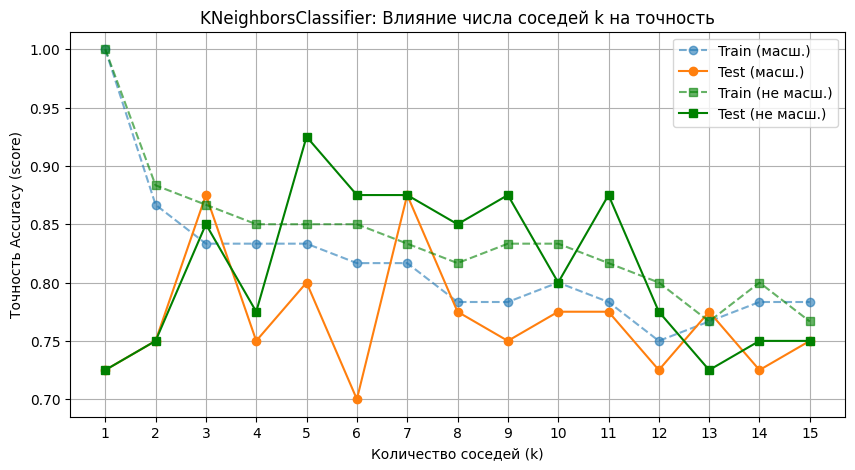

Лучшие параметры KNeighborsClassifier: {'данные': 'Оригинальные', 'n_neighbors': 5, 'weights': 'uniform'}
Было (стандартный масштабированный, k = 5): 0.8000
Стало (настроенный KNN, k = 5): 0.9250


In [14]:
# 1. График зависимости Accuracy от числа соседей k (масштабированные и сырые данные)
k_range_c = range(1, 16)
train_c_sc, test_c_sc = [], []
train_c_or, test_c_or = [], []

for k in k_range_c:
    knn_sc = KNeighborsClassifier(n_neighbors=k).fit(X_train_c_scaled, y_train_c)
    train_c_sc.append(knn_sc.score(X_train_c_scaled, y_train_c))
    test_c_sc.append(knn_sc.score(X_test_c_scaled, y_test_c))
    
    knn_or = KNeighborsClassifier(n_neighbors=k).fit(X_train_c, y_train_c)
    train_c_or.append(knn_or.score(X_train_c, y_train_c))
    test_c_or.append(knn_or.score(X_test_c, y_test_c))

plt.figure(figsize=(10, 5))
plt.plot(k_range_c, train_c_sc, '--o', alpha=0.6, label='Train (масш.)')
plt.plot(k_range_c, test_c_sc, '-o', label='Test (масш.)')
plt.plot(k_range_c, train_c_or, '--s', alpha=0.6, color='green', label='Train (не масш.)')
plt.plot(k_range_c, test_c_or, '-s', color='green', label='Test (не масш.)')
plt.xlabel('Количество соседей (k)')
plt.ylabel('Точность Accuracy (score)')
plt.title('KNeighborsClassifier: Влияние числа соседей k на точность')
plt.xticks(k_range_c)
plt.legend()
plt.grid(True)
plt.show()

# 2. Перебор параметров для поиска лучшего KNN
best_knn_c_score = -999
best_knn_c_params = {}

for data_name, (X_tr, X_te) in [('Масштабированные', (X_train_c_scaled, X_test_c_scaled)), ('Оригинальные', (X_train_c, X_test_c))]:
    for k in range(1, 21):
        for w in ('uniform', 'distance'):
            knn = KNeighborsClassifier(n_neighbors=k, weights=w)
            knn.fit(X_tr, y_train_c)
            score = knn.score(X_te, y_test_c)
            
            if score > best_knn_c_score:
                best_knn_c_score = score
                best_knn_c_params = {'данные': data_name, 'n_neighbors': k, 'weights': w}

print('Лучшие параметры KNeighborsClassifier:', best_knn_c_params)
print(f"Было (стандартный масштабированный, k = {knn_clf_base.n_neighbors}): {acc_knn_base:.4f}")
print(f"Стало (настроенный KNN, k = {best_knn_c_params['n_neighbors']}): {best_knn_c_score:.4f}")


#### Анализ графика и настройка KNeighborsClassifier:
* **При `k = 1`** модель переобучается: на обучении (`Train`) точность равна `1.0` (каждая точка находит саму себя), а на тесте падает до `0.725`.
* **Оптимальный результат — `Accuracy = 0.9250` при `k = 5` на оригинальных данных** (зелёный пик на графике): опрос 5 ближайших соседей сглаживает случайный шум одиночных точек. На масштабированных данных пик ниже (`0.875` при `k = 3` и `k = 7`), так как слабый признак `f1` после выравнивания масштаба вносит лишний шум в расчёт расстояний.
* **При `k > 11`** точность обоих вариантов снижается (недообучение), так как в обучающей выборке всего 60 строк и модель начинает учитывать слишком далёких соседей из чужих классов.


Лучший KNN (масш., k=3)    -> Accuracy: 0.8750
Лучший KNN (не масш., k=5) -> Accuracy: 0.9250

Отчёт по метрикам (лучший KNN на сырых данных, k=5):
              precision    recall  f1-score   support

           0       0.81      1.00      0.90        13
           1       1.00      0.86      0.92        14
           2       1.00      0.92      0.96        13

    accuracy                           0.93        40
   macro avg       0.94      0.93      0.93        40
weighted avg       0.94      0.93      0.93        40



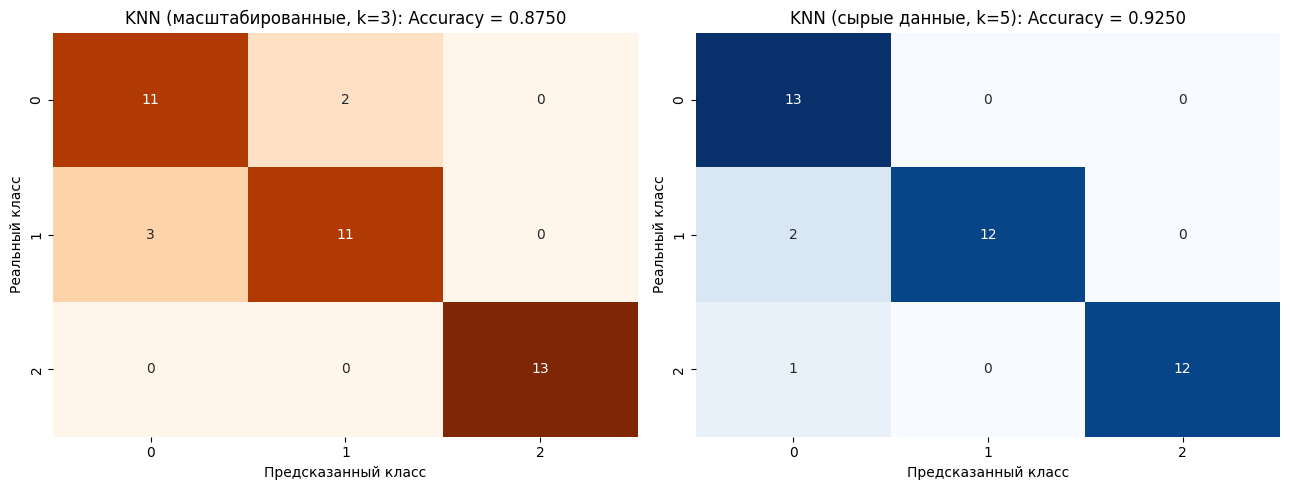

In [17]:
# 1. Лучший KNN на МАСШТАБИРОВАННЫХ данных (пик оранжевой линии при k=3)
knn_clf_scaled_best = KNeighborsClassifier(n_neighbors=3, weights='uniform')
knn_clf_scaled_best.fit(X_train_c_scaled, y_train_c)
y_pred_knn_c_sc = knn_clf_scaled_best.predict(X_test_c_scaled)
acc_knn_c_sc = knn_clf_scaled_best.score(X_test_c_scaled, y_test_c)

# 2. Лучший KNN на ОРИГИНАЛЬНЫХ (сырых) данных (пик зелёной линии при k=5)
knn_clf_best = KNeighborsClassifier(n_neighbors=5, weights='uniform')
knn_clf_best.fit(X_train_c, y_train_c)
y_pred_knn_c_best = knn_clf_best.predict(X_test_c)
acc_knn_best = knn_clf_best.score(X_test_c, y_test_c)

print(f'Лучший KNN (масш., k=3)    -> Accuracy: {acc_knn_c_sc:.4f}')
print(f'Лучший KNN (не масш., k=5) -> Accuracy: {acc_knn_best:.4f}\n')

print('Отчёт по метрикам (лучший KNN на сырых данных, k=5):')
print(classification_report(y_test_c, y_pred_knn_c_best))

# Рисуем две матрицы ошибок рядом
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

cm_knn_sc = confusion_matrix(y_test_c, y_pred_knn_c_sc)
sns.heatmap(cm_knn_sc, annot=True, fmt='d', cmap='Oranges', cbar=False, ax=ax1)
ax1.set_xlabel('Предсказанный класс')
ax1.set_ylabel('Реальный класс')
ax1.set_title(f'KNN (масштабированные, k=3): Accuracy = {acc_knn_c_sc:.4f}')

cm_knn_or = confusion_matrix(y_test_c, y_pred_knn_c_best)
sns.heatmap(cm_knn_or, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax2)
ax2.set_xlabel('Предсказанный класс')
ax2.set_ylabel('Реальный класс')
ax2.set_title(f'KNN (сырые данные, k=5): Accuracy = {acc_knn_best:.4f}')

plt.tight_layout()
plt.show()


#### Итоговый вывод по KNeighborsClassifier:
* Сравнение матриц ошибок подтверждает преимущество **сырых данных при `k = 5` (`Accuracy = 0.9250`)** над масштабированными (`0.8750` при `k = 3`): на правой синей матрице модель безошибочно распознала все **13 из 13** объектов класса `0`, **12 из 14** класса `1` и **12 из 13** класса `2` (всего 37 верных ответов из 40).
* Причина более высокой точности на сырых данных в том, что после масштабирования слабый признак `f1` (корреляция `0.30`) получает такой же вес при подсчёте расстояний, как и три сильных признака (`f0`, `f3`, `f4`), что добавляет лишний шум.
* По итоговому качеству **`KNeighborsClassifier` (`0.9250`) уверенно обогнал `RandomForestClassifier` (`0.8250`)**.


## 6. Итоговое сравнение моделей и оценка качества (Задача классификации)

Сведём результаты обеих моделей классификации (до и после настройки гиперпараметров) в общую таблицу по ключевым метрикам (`Accuracy / score()`, `Precision`, `Recall`, `F1-score`).


* support — сколько объектов этого класса было в тесте.
* precision — если модель назвала класс X, как часто она права (нет ложных срабатываний).
* recall — сколько процентов от всех реальных объектов класса X модель смогла найти.
* f1-score — общий баланс между precision и recall.


In [20]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Фиксируем лучший RandomForestClassifier (по найденным параметрам best_rf_c_params)
rf_clf_best = RandomForestClassifier(**best_rf_c_params, random_state=42)
rf_clf_best.fit(X_train_c, y_train_c)
y_pred_rf_c_best = rf_clf_best.predict(X_test_c)
acc_rf_best = rf_clf_best.score(X_test_c, y_test_c)

# Собираем сводную таблицу результатов моделей классификации
results_clf = pd.DataFrame({
    'Модель': [
        'KNeighborsClassifier',
        'RandomForestClassifier'
    ],
    'Базовый Accuracy (score)': [
        round(acc_knn_base, 4),
        round(acc_rf_base, 4)
    ],
    'Лучший Accuracy (score)': [
        round(acc_knn_best, 4),
        round(acc_rf_best, 4)
    ],
    'Precision (macro)': [
        round(precision_score(y_test_c, y_pred_knn_c_best, average='macro'), 4),
        round(precision_score(y_test_c, y_pred_rf_c_best, average='macro'), 4)
    ],
    'Recall (macro)': [
        round(recall_score(y_test_c, y_pred_knn_c_best, average='macro'), 4),
        round(recall_score(y_test_c, y_pred_rf_c_best, average='macro'), 4)
    ],
    'F1-score (macro)': [
        round(f1_score(y_test_c, y_pred_knn_c_best, average='macro'), 4),
        round(f1_score(y_test_c, y_pred_rf_c_best, average='macro'), 4)
    ]
}).sort_values(by='Лучший Accuracy (score)', ascending=False).reset_index(drop=True)

display(results_clf)


,Модель,Базовый Accuracy (score),Лучший Accuracy (score),Precision (macro),Recall (macro),F1-score (macro)
0,KNeighborsClassifier,0.8,0.925,0.9375,0.9267,0.9265
1,RandomForestClassifier,0.8,0.825,0.8209,0.8260,0.8211


### Итоговый вывод по Заданию №2 (Задача классификации)

1. **Победитель:** Наилучший результат показала настроенная модель ближайших соседей **`KNeighborsClassifier(n_neighbors=5, weights='uniform')` на сырых данных** с точностью **`Accuracy (score) = 0.9250`**. На втором месте — настроенный **`RandomForestClassifier` (`Accuracy = 0.8250`, `F1-score = 0.8211`)**.
2. **Почему победил KNN:** После удаления шумовых столбцов (`f2`, `f5`) и полного дубликата (`f6`) остались 4 информативных признака (`f0`, `f1`, `f3`, `f4`), в пространстве которых объекты разных классов образуют чёткие компактные группы. Поэтому поиск 5 ближайших соседей на сырых данных (где слабый признак `f1` не раздут масштабированием) дал гораздо более точный результат, чем ступенчатые разбиения деревьев на небольшой выборке из 60 обучающих строк.
3. **Влияние предобработки:** Отбор признаков по матрице корреляций и сохранение пропорции классов при разбиении выборки (`stratify=y`) позволили добиться высокой точности без переобучения.
